<a href="https://colab.research.google.com/github/Yogeshjagtap210/Artificial-intelligence-/blob/main/generate_leads_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install faker -q
import random
import pandas as pd
from faker import Faker

random.seed(42)
Faker.seed(42)
fake = Faker("en_IN")

N = 55_000
SOURCES = {
    "Source A": (0.03, 0.04, 0.02, 0.10),
    "Source B": (0.05, 0.08, 0.04, 0.20),
    "Source C": (0.14, 0.15, 0.09, 0.35),
    "Source D": (0.07, 0.10, 0.05, 0.25),
    "Source E": (0.10, 0.12, 0.07, 0.30),
    "Manual":   (0.18, 0.20, 0.12, 0.40),
}
INDUSTRIES = ["Information Technology", "Healthcare", "Manufacturing",
              "Financial Services", "Retail", "Education", "Logistics"]
INDUSTRY_VARIANTS = {
    "Information Technology": ["IT", "Information Technology", "it services", "I.T."],
    "Healthcare": ["Healthcare", "Health Care", "healthcare "],
    "Manufacturing": ["Manufacturing", "manufacturing", "Mfg"],
    "Financial Services": ["Financial Services", "Finance", "BFSI"],
    "Retail": ["Retail", "retail", "Retail & Ecommerce"],
    "Education": ["Education", "EdTech", "education"],
    "Logistics": ["Logistics", "Supply Chain", "logistics"],
}
SIZES = ["1-10", "11-50", "51-200", "201-500", "501-1000", "1000+"]
TITLES = ["CEO", "Founder", "CTO", "VP Sales", "Head of Marketing",
          "HR Manager", "Operations Manager", "Data Analyst", "Director"]
TITLE_VARIANTS = {"CEO": ["CEO", "Chief Executive Officer", "ceo"],
                  "CTO": ["CTO", "Chief Technology Officer"],
                  "VP Sales": ["VP Sales", "Vice President - Sales", "VP of Sales"]}
COUNTRIES = {"India": ["India", "IN", "india", "INDIA"],
             "United States": ["United States", "USA", "US"],
             "United Kingdom": ["United Kingdom", "UK"],
             "UAE": ["UAE", "United Arab Emirates"]}
CLIENTS = [f"CL{str(i).zfill(3)}" for i in range(1, 41)]


def make_record(i):
    source = random.choices(list(SOURCES), weights=[25, 20, 15, 15, 15, 10])[0]
    _, miss_e, bad_e, miss_p = SOURCES[source]
    first, last = fake.first_name(), fake.last_name()
    company = fake.company().replace(",", "")
    domain = company.split()[0].lower().replace(" ", "") + ".com"
    industry = random.choice(INDUSTRIES)
    title = random.choice(TITLES)
    country = random.choice(list(COUNTRIES))

    r = random.random()
    if r < miss_e:
        email = None
    elif r < miss_e + bad_e:
        email = random.choice([f"{first}.{last}@{domain}".replace(".", "", 1),
                               f"{first}{last}@", f"{first}.{last}@{domain.split('.')[0]}",
                               f"{first} {last}@{domain}"])
    else:
        email = f"{first}.{last}@{domain}".lower()

    phone = None if random.random() < miss_p else fake.phone_number()

    return {
        "lead_id": i,
        "client_id": random.choice(CLIENTS),
        "source": source,
        "company_name": company,
        "industry": random.choice(INDUSTRY_VARIANTS[industry]),
        "company_size": random.choice(SIZES),
        "country": random.choice(COUNTRIES[country]),
        "contact_name": f"{first} {last}",
        "job_title": random.choice(TITLE_VARIANTS.get(title, [title])),
        "email": email,
        "phone": phone,
        "date_collected": fake.date_between(start_date="-12M", end_date="today"),
    }


rows = [make_record(i) for i in range(1, N + 1)]
df = pd.DataFrame(rows)

dups = []
for _, row in df.iterrows():
    if random.random() < SOURCES[row["source"]][0]:
        d = row.to_dict()
        d["contact_name"] = random.choice([d["contact_name"].upper(),
                                           d["contact_name"] + " ",
                                           d["contact_name"]])
        if isinstance(d["email"], str) and random.random() < 0.5:
            d["email"] = d["email"].upper()
        dups.append(d)
dups_df = pd.DataFrame(dups)
dups_df["lead_id"] = range(N + 1, N + 1 + len(dups_df))

final = pd.concat([df, dups_df]).sample(frac=1, random_state=1).reset_index(drop=True)
final.to_csv("raw_leads.csv", index=False)

print(f"Rows: {len(final):,}  (duplicates injected: {len(dups_df):,})")

Rows: 59,486  (duplicates injected: 4,486)


In [5]:
import re
import pandas as pd

df = pd.read_csv("raw_leads.csv")
report = {"raw_rows": len(df)}

# STEP 1: Fix spaces and capital letters
df["contact_name"] = df["contact_name"].str.strip().str.title()
df["email"] = df["email"].str.strip().str.lower()
df["company_name"] = df["company_name"].str.strip()

# STEP 2: Make labels the same
industry_map = {
    "it": "Information Technology", "i.t.": "Information Technology",
    "it services": "Information Technology",
    "information technology": "Information Technology",
    "healthcare": "Healthcare", "health care": "Healthcare",
    "manufacturing": "Manufacturing", "mfg": "Manufacturing",
    "financial services": "Financial Services", "finance": "Financial Services",
    "bfsi": "Financial Services",
    "retail": "Retail", "retail & ecommerce": "Retail",
    "education": "Education", "edtech": "Education",
    "logistics": "Logistics", "supply chain": "Logistics",
}
df["industry"] = df["industry"].str.strip().str.lower().map(industry_map)

country_map = {
    "india": "India", "in": "India",
    "united states": "United States", "usa": "United States", "us": "United States",
    "united kingdom": "United Kingdom", "uk": "United Kingdom",
    "uae": "UAE", "united arab emirates": "UAE",
}
df["country"] = df["country"].str.strip().str.lower().map(country_map)

title_map = {
    "ceo": "CEO", "chief executive officer": "CEO",
    "cto": "CTO", "chief technology officer": "CTO",
    "vp sales": "VP Sales", "vice president - sales": "VP Sales",
    "vp of sales": "VP Sales",
}
df["job_title"] = df["job_title"].str.strip()
df["job_title"] = df["job_title"].str.lower().map(title_map).fillna(df["job_title"])

report["unmapped_ind

SyntaxError: unterminated string literal (detected at line 44) (681042005.py, line 44)

In [8]:
import re
import pandas as pd

df = pd.read_csv("raw_leads.csv")
report = {"raw_rows": len(df)}

df["contact_name"] = df["contact_name"].str.strip().str.title()
df["email"] = df["email"].str.strip().str.lower()
df["company_name"] = df["company_name"].str.strip()
print("Cell 1 done:", len(df), "rows")

Cell 1 done: 59486 rows


In [9]:
industry_map = {
    "it": "Information Technology", "i.t.": "Information Technology",
    "it services": "Information Technology",
    "information technology": "Information Technology",
    "healthcare": "Healthcare", "health care": "Healthcare",
    "manufacturing": "Manufacturing", "mfg": "Manufacturing",
    "financial services": "Financial Services", "finance": "Financial Services",
    "bfsi": "Financial Services",
    "retail": "Retail", "retail & ecommerce": "Retail",
    "education": "Education", "edtech": "Education",
    "logistics": "Logistics", "supply chain": "Logistics",
}
df["industry"] = df["industry"].str.strip().str.lower().map(industry_map)
report["unmapped_industry"] = int(df["industry"].isna().sum())
print("Cell 2 done. Unmapped industry:", report["unmapped_industry"])

Cell 2 done. Unmapped industry: 0


In [10]:
country_map = {
    "india": "India", "in": "India",
    "united states": "United States", "usa": "United States", "us": "United States",
    "united kingdom": "United Kingdom", "uk": "United Kingdom",
    "uae": "UAE", "united arab emirates": "UAE",
}
df["country"] = df["country"].str.strip().str.lower().map(country_map)

title_map = {
    "ceo": "CEO", "chief executive officer": "CEO",
    "cto": "CTO", "chief technology officer": "CTO",
    "vp sales": "VP Sales", "vice president - sales": "VP Sales",
    "vp of sales": "VP Sales",
}
df["job_title"] = df["job_title"].str.strip()
df["job_title"] = df["job_title"].str.lower().map(title_map).fillna(df["job_title"])
report["unmapped_country"] = int(df["country"].isna().sum())
print("Cell 3 done. Unmapped country:", report["unmapped_country"])

Cell 3 done. Unmapped country: 0


In [11]:
pattern = r"^[a-z0-9._%+-]+@[a-z0-9.-]+\.[a-z]{2,}$"
df["email_valid"] = df["email"].apply(
    lambda e: bool(re.match(pattern, e)) if isinstance(e, str) else False
)
report["missing_email"] = int(df["email"].isna().sum())
report["invalid_email_format"] = int((df["email"].notna() & ~df["email_valid"]).sum())

df = df.sort_values("lead_id")
has_email = df["email"].notna()
dup = df[has_email].duplicated(subset=["email"], keep="first")
dup_idx = dup[dup].index
report["duplicates_removed"] = len(dup_idx)
df = df.drop(index=dup_idx)

df["qualified"] = (df["email_valid"] & df["industry"].notna()
                   & df["country"].notna() & df["phone"].notna())
report["clean_rows"] = len(df)
report["qualified_rows"] = int(df["qualified"].sum())
df.to_csv("clean_leads.csv", index=False)

for k, v in report.items():
    print(f"{k:25s} {v:,}")
print("qualified_rate", f"{report['qualified_rows']/report['clean_rows']:.1%}")

raw_rows                  59,486
unmapped_industry         0
unmapped_country          0
missing_email             6,025
invalid_email_format      2,848
duplicates_removed        3,943
clean_rows                55,543
qualified_rows            35,990
qualified_rate 64.8%


In [12]:
import sqlite3, pandas as pd
conn = sqlite3.connect("leads.db")
pd.read_csv("raw_leads.csv").to_sql("raw_leads", conn, if_exists="replace", index=False)
pd.read_csv("clean_leads.csv").to_sql("clean_leads", conn, if_exists="replace", index=False)
print("Database ready")

Database ready


In [13]:
q1 = """
SELECT r.source,
       r.raw_rows,
       c.clean_rows,
       r.raw_rows - c.clean_rows AS duplicates_removed,
       ROUND(100.0 * (r.raw_rows - c.clean_rows) / r.raw_rows, 1) AS duplicate_pct
FROM (SELECT source, COUNT(*) AS raw_rows FROM raw_leads GROUP BY source) r
JOIN (SELECT source, COUNT(*) AS clean_rows FROM clean_leads GROUP BY source) c
  ON r.source = c.source
ORDER BY duplicate_pct DESC
"""
pd.read_sql(q1, conn)

,source,raw_rows,clean_rows,duplicates_removed,duplicate_pct
0,Manual,6441,5632,809,12.6
1,Source C,9350,8361,989,10.6
2,Source E,8996,8297,699,7.8
3,Source D,8990,8454,536,6.0
4,Source B,11703,11160,543,4.6
5,Source A,14006,13639,367,2.6


In [14]:
q2 = """
SELECT source,
       COUNT(*) AS leads,
       ROUND(100.0 * SUM(email_valid) / COUNT(*), 1) AS valid_email_pct,
       ROUND(100.0 * SUM(qualified) / COUNT(*), 1) AS qualified_pct
FROM clean_leads
GROUP BY source
ORDER BY qualified_pct DESC
"""
pd.read_sql(q2, conn)

,source,leads,valid_email_pct,qualified_pct
0,Source A,13639,94.0,84.5
1,Source B,11160,88.4,71.0
2,Source D,8454,85.9,64.5
3,Source E,8297,81.1,56.6
4,Source C,8361,77.2,49.3
5,Manual,5632,67.9,40.4


In [15]:
q3 = """
SELECT 'Raw' AS stage, COUNT(*) AS leads FROM raw_leads
UNION ALL SELECT 'After removing duplicates', COUNT(*) FROM clean_leads
UNION ALL SELECT 'Valid email', COUNT(*) FROM clean_leads WHERE email_valid = 1
UNION ALL SELECT 'Qualified', COUNT(*) FROM clean_leads WHERE qualified = 1
"""
pd.read_sql(q3, conn)

,stage,leads
0,Raw,59486
1,After removing duplicates,55543
2,Valid email,46955
3,Qualified,35990


In [17]:
summary = pd.read_sql("""
SELECT
    source,
    COUNT(*) AS leads,
    SUM(email_valid) AS valid_emails,
    SUM(qualified) AS qualified_leads,
    ROUND(100.0 * SUM(qualified) / COUNT(*), 1) AS qualified_pct
FROM clean_leads
GROUP BY source
ORDER BY qualified_pct DESC
""", conn)


In [18]:
summary.to_csv("source_quality_summary.csv", index=False)
print("Summary saved")

Summary saved


In [19]:
summary = pd.read_sql("""
SELECT
    source,
    COUNT(*) AS leads,
    SUM(email_valid) AS valid_emails,
    SUM(qualified) AS qualified_leads,
    ROUND(100.0 * SUM(qualified) / COUNT(*), 1) AS qualified_pct
FROM clean_leads
GROUP BY source
ORDER BY qualified_pct DESC
""", conn)

summary

,source,leads,valid_emails,qualified_leads,qualified_pct
0,Source A,13639,12824,11520,84.5
1,Source B,11160,9866,7926,71.0
2,Source D,8454,7259,5450,64.5
3,Source E,8297,6730,4700,56.6
4,Source C,8361,6453,4118,49.3
5,Manual,5632,3823,2276,40.4


In [20]:
summary.to_csv("source_quality_summary.csv", index=False)
print("Summary saved successfully")

Summary saved successfully


In [21]:
summary = pd.read_sql("""
SELECT
    source,
    COUNT(*) AS leads,
    SUM(email_valid) AS valid_emails,
    SUM(qualified) AS qualified_leads,
    ROUND(100.0 * SUM(qualified) / COUNT(*), 1) AS qualified_pct
FROM clean_leads
GROUP BY source
ORDER BY qualified_pct DESC
""", conn)

summary

,source,leads,valid_emails,qualified_leads,qualified_pct
0,Source A,13639,12824,11520,84.5
1,Source B,11160,9866,7926,71.0
2,Source D,8454,7259,5450,64.5
3,Source E,8297,6730,4700,56.6
4,Source C,8361,6453,4118,49.3
5,Manual,5632,3823,2276,40.4


In [22]:
raw_count = pd.read_sql(
    "SELECT COUNT(*) AS n FROM raw_leads", conn
)["n"][0]

clean_count = pd.read_sql(
    "SELECT COUNT(*) AS n FROM clean_leads", conn
)["n"][0]

duplicate_count = raw_count - clean_count

valid_email_count = pd.read_sql(
    "SELECT COUNT(*) AS n FROM clean_leads WHERE email_valid = 1", conn
)["n"][0]

qualified_count = pd.read_sql(
    "SELECT COUNT(*) AS n FROM clean_leads WHERE qualified = 1", conn
)["n"][0]

qualified_rate = qualified_count / clean_count * 100

print("Raw Leads:", f"{raw_count:,}")
print("Clean Leads:", f"{clean_count:,}")
print("Duplicates Removed:", f"{duplicate_count:,}")
print("Valid Emails:", f"{valid_email_count:,}")
print("Qualified Leads:", f"{qualified_count:,}")
print("Qualified Rate:", f"{qualified_rate:.1f}%")

Raw Leads: 59,486
Clean Leads: 55,543
Duplicates Removed: 3,943
Valid Emails: 46,955
Qualified Leads: 35,990
Qualified Rate: 64.8%


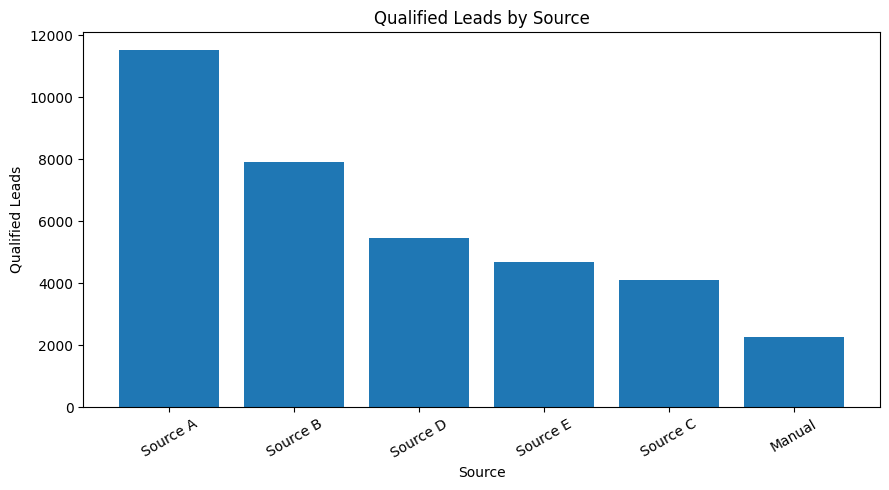

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(summary["source"], summary["qualified_leads"])

plt.title("Qualified Leads by Source")
plt.xlabel("Source")
plt.ylabel("Qualified Leads")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

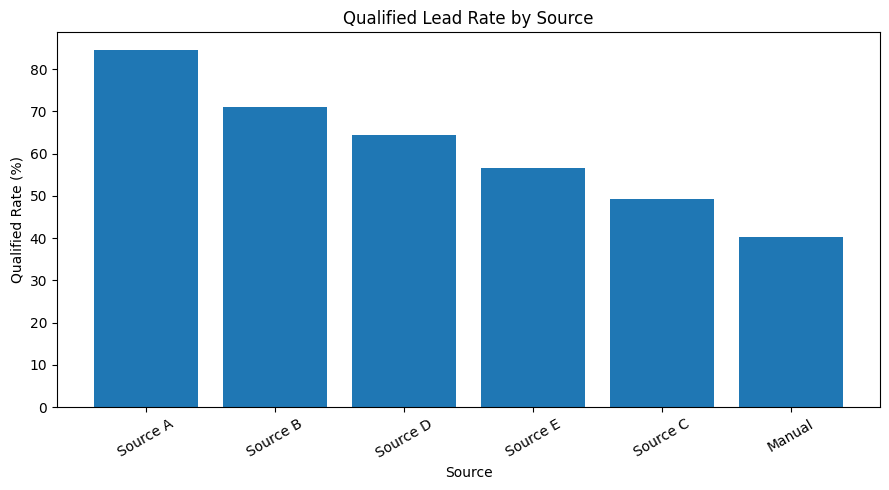

In [24]:
plt.figure(figsize=(9, 5))

plt.bar(summary["source"], summary["qualified_pct"])

plt.title("Qualified Lead Rate by Source")
plt.xlabel("Source")
plt.ylabel("Qualified Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [25]:
funnel = pd.DataFrame({
    "stage": [
        "Raw Leads",
        "After Duplicates",
        "Valid Email",
        "Qualified"
    ],
    "leads": [
        raw_count,
        clean_count,
        valid_email_count,
        qualified_count
    ]
})

funnel

,stage,leads
0,Raw Leads,59486
1,After Duplicates,55543
2,Valid Email,46955
3,Qualified,35990


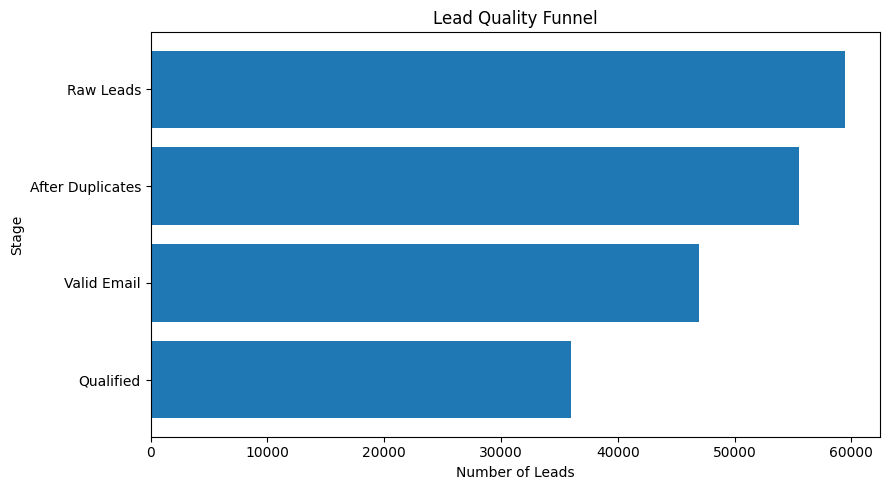

In [26]:
plt.figure(figsize=(9, 5))

plt.barh(funnel["stage"], funnel["leads"])

plt.title("Lead Quality Funnel")
plt.xlabel("Number of Leads")
plt.ylabel("Stage")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [27]:
duplicate_data = pd.read_sql("""
SELECT
    r.source,
    r.raw_rows,
    c.clean_rows,
    r.raw_rows - c.clean_rows AS duplicates_removed,
    ROUND(
        100.0 * (r.raw_rows - c.clean_rows) / r.raw_rows,
        1
    ) AS duplicate_pct
FROM
    (SELECT source, COUNT(*) AS raw_rows
     FROM raw_leads
     GROUP BY source) r
JOIN
    (SELECT source, COUNT(*) AS clean_rows
     FROM clean_leads
     GROUP BY source) c
ON r.source = c.source
ORDER BY duplicate_pct DESC
""", conn)

duplicate_data

,source,raw_rows,clean_rows,duplicates_removed,duplicate_pct
0,Manual,6441,5632,809,12.6
1,Source C,9350,8361,989,10.6
2,Source E,8996,8297,699,7.8
3,Source D,8990,8454,536,6.0
4,Source B,11703,11160,543,4.6
5,Source A,14006,13639,367,2.6


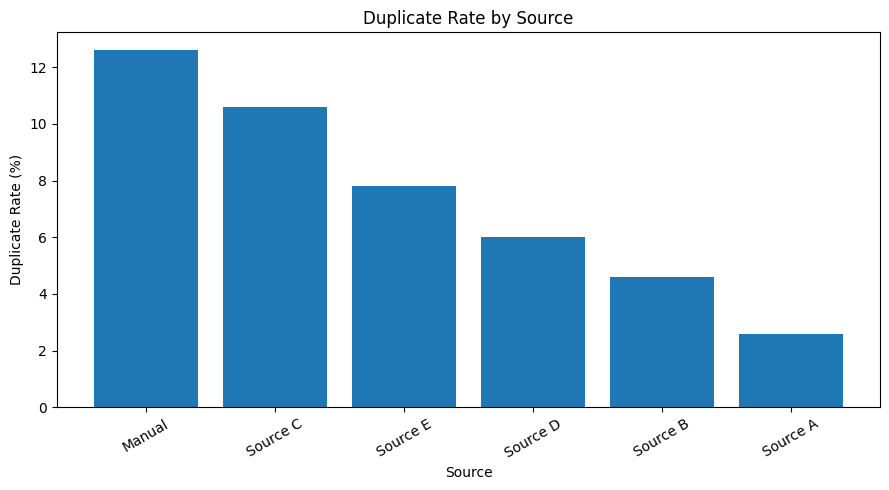

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    duplicate_data["source"],
    duplicate_data["duplicate_pct"]
)

plt.title("Duplicate Rate by Source")
plt.xlabel("Source")
plt.ylabel("Duplicate Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

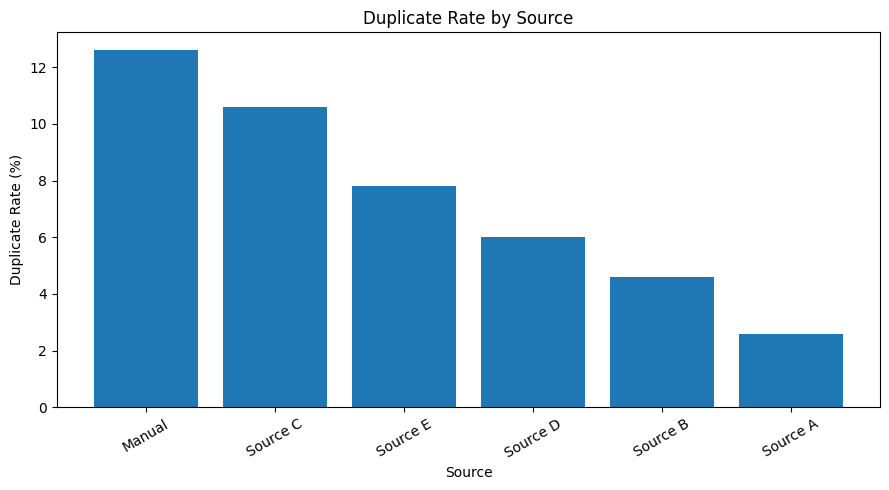

In [29]:
plt.figure(figsize=(9, 5))

plt.bar(
    duplicate_data["source"],
    duplicate_data["duplicate_pct"]
)

plt.title("Duplicate Rate by Source")
plt.xlabel("Source")
plt.ylabel("Duplicate Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [30]:
print("===== FINAL PROJECT FINDINGS =====")
print()
print("1. Duplicate Quality:")
print("Manual has the highest duplicate rate at 12.6%.")
print("Source A has the lowest duplicate rate at 2.6%.")
print()
print("2. Lead Quality:")
print("Source A has the highest qualified-lead rate at 84.5%.")
print("Manual has the lowest qualified-lead rate at 40.4%.")
print()
print("3. Overall Funnel:")
print("59,486 raw leads were collected.")
print("55,543 leads remained after duplicate removal.")
print("46,955 leads had valid emails.")
print("35,990 leads were qualified.")
print("Overall qualified rate: 64.8%.")

===== FINAL PROJECT FINDINGS =====

1. Duplicate Quality:
Manual has the highest duplicate rate at 12.6%.
Source A has the lowest duplicate rate at 2.6%.

2. Lead Quality:
Source A has the highest qualified-lead rate at 84.5%.
Manual has the lowest qualified-lead rate at 40.4%.

3. Overall Funnel:
59,486 raw leads were collected.
55,543 leads remained after duplicate removal.
46,955 leads had valid emails.
35,990 leads were qualified.
Overall qualified rate: 64.8%.


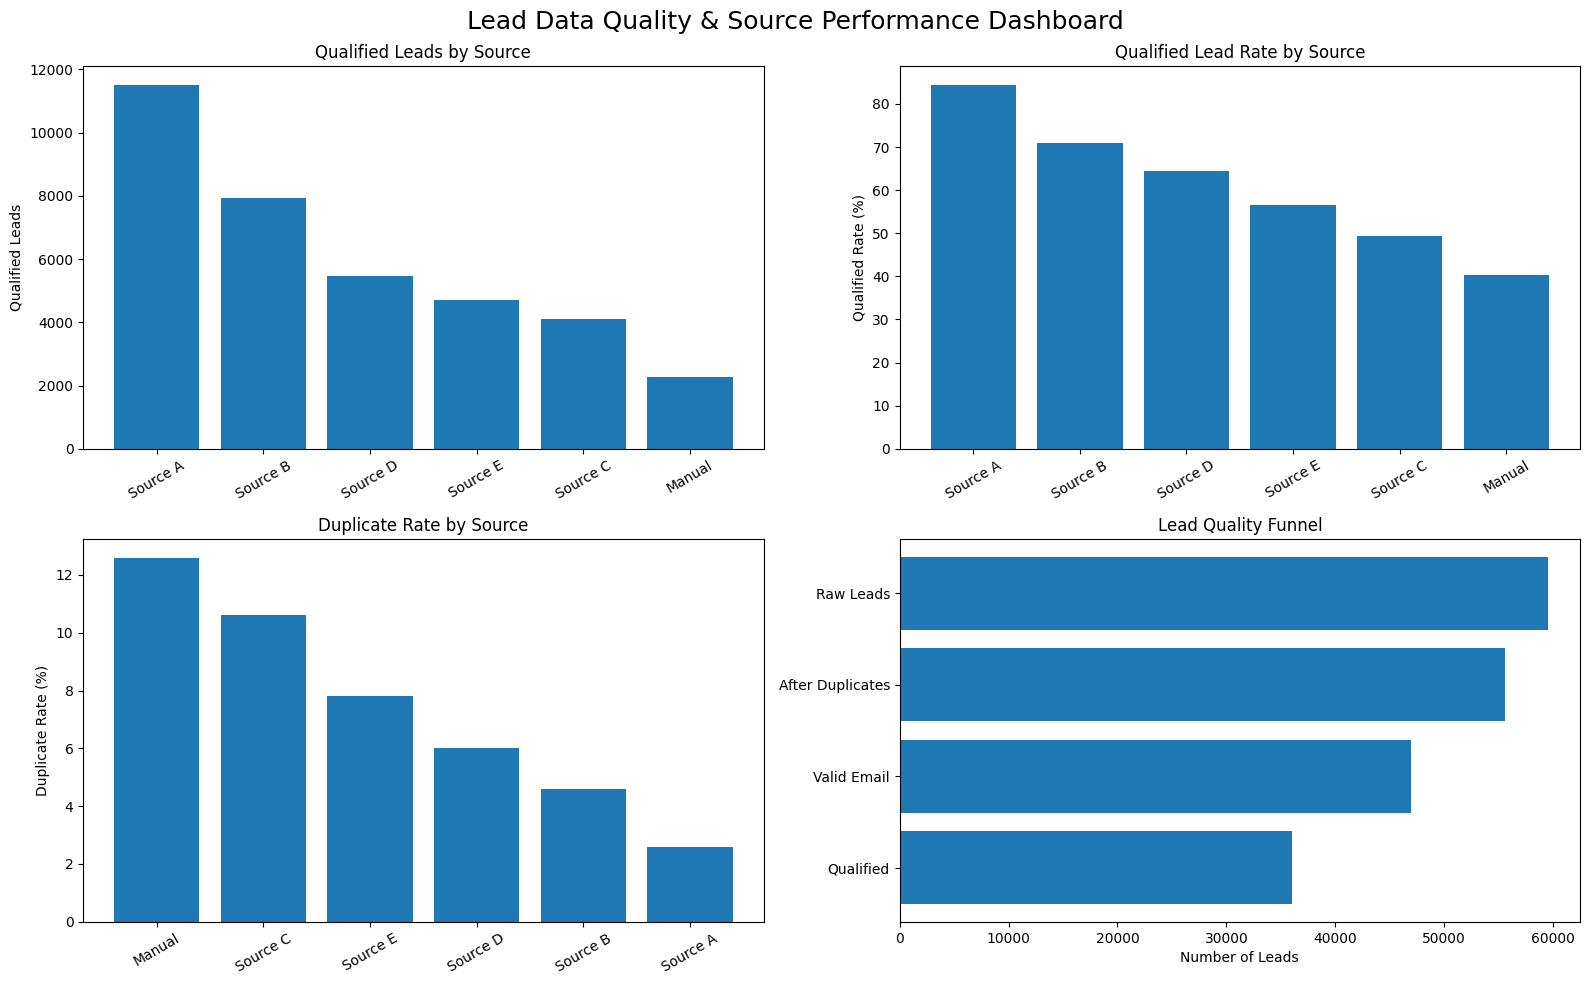

In [31]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Qualified leads by source
axes[0, 0].bar(summary["source"], summary["qualified_leads"])
axes[0, 0].set_title("Qualified Leads by Source")
axes[0, 0].set_ylabel("Qualified Leads")
axes[0, 0].tick_params(axis="x", rotation=30)

# 2. Qualified rate
axes[0, 1].bar(summary["source"], summary["qualified_pct"])
axes[0, 1].set_title("Qualified Lead Rate by Source")
axes[0, 1].set_ylabel("Qualified Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=30)

# 3. Duplicate rate
axes[1, 0].bar(
    duplicate_data["source"],
    duplicate_data["duplicate_pct"]
)
axes[1, 0].set_title("Duplicate Rate by Source")
axes[1, 0].set_ylabel("Duplicate Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=30)

# 4. Funnel
axes[1, 1].barh(funnel["stage"], funnel["leads"])
axes[1, 1].set_title("Lead Quality Funnel")
axes[1, 1].set_xlabel("Number of Leads")
axes[1, 1].invert_yaxis()

plt.suptitle(
    "Lead Data Quality & Source Performance Dashboard",
    fontsize=18
)

plt.tight_layout()
plt.show()